# Matrix emulation, shot noise and parameter shifts

The models are trained on a torch matrix emulation of the photonic circuit. This notebook compares it with
strawberryfields sampling and with the shot-noise model used for Fig. 8, and compares parameter-shift rules.

In [1]:
import warnings
warnings.filterwarnings("ignore", message=".*pkg_resources.*")           # emitted when strawberryfields is imported
warnings.filterwarnings("ignore", message=".*disconnected components.*")  # sf: programs on unentangled modes

import matplotlib.pyplot as plt
import numpy as np
import torch

from cv_relational_learning.circuits import RotationSwapCircuit, RotationSwapShotCircuit
from cv_relational_learning.datasets import load_dataset
from cv_relational_learning.fock import swap_operator
from cv_relational_learning.gradients import generalised_parameter_shift, parameter_shift
from cv_relational_learning.sf_simulation import SFRotationSwapCircuit

np.random.seed(0)     # strawberryfields samples photon counts with numpy's global RNG
torch.manual_seed(0)  # Gaussian shot noise of RotationSwapShotCircuit
COLORS = {"sf": "#2a78d6", "clt": "#eb6834", "general": "#1baf7a"}

## 1. The model

The SWAP model rotates the second state of a pair by $\theta$ and measures SWAP,
$f(\theta) = |\langle\psi|R(\theta)|\phi\rangle|^2$. We use a class-1 pair from the small cutoff-10 dataset.

In [2]:
d = 10
train, _, _ = load_dataset("hidden_rotation", d, n_train=20, n_val=0, n_test=0)
idx = 2
x, label = train.data[idx], int(train.targets[idx])

probs = (x.abs() ** 2).numpy()
n_total = np.add.outer(np.arange(d), np.arange(d))
print(f"datapoint {idx}: class {label}, ket shape {tuple(x.shape)}, norm^2 = {probs.sum():.5f}, "
      f"mean total photon number = {(probs * n_total).sum():.2f}")

datapoint 2: class 1, ket shape (10, 10), norm^2 = 0.99984, mean total photon number = 4.55


Three simulators of the same model:

- `RotationSwapCircuit`: exact, by matrix multiplication;
- `SFRotationSwapCircuit`: strawberryfields with `n_shots` SWAP tests;
- `RotationSwapShotCircuit`: exact value plus Gaussian noise of standard deviation $\sqrt{(1-f^2)/N}$ (Fig. 8).

In [3]:
n_shots = 400
matrix_circuit = RotationSwapCircuit(d, swap_operator(d))
sf_circuit = SFRotationSwapCircuit(d, n_shots)
clt_circuit = RotationSwapShotCircuit(d, swap_operator(d), n_shots)

def f_exact(theta):
    return matrix_circuit.forward(torch.tensor([theta], dtype=torch.float64), x).item()

print(f"f(-1) = {f_exact(-1.0):.4f}   f(0) = {f_exact(0.0):.4f}")

f(-1) = 0.9998   f(0) = 0.2313


## 2. Three simulators, one curve

In [4]:
thetas = np.linspace(-np.pi, np.pi, 24, endpoint=False)
f_matrix = np.array([f_exact(t) for t in thetas])
f_sf = np.array([sf_circuit.forward(np.array([t]), x) for t in thetas])
f_clt = np.array([clt_circuit.forward(np.array([t]), x).item() for t in thetas])
sigma = np.sqrt((1 - f_matrix**2) / n_shots)

for name, values in (("strawberryfields", f_sf), ("CLT model", f_clt)):
    z = (values - f_matrix) / sigma
    print(f"{name:>16}: RMS of (estimate - exact) / sigma = {np.sqrt(np.mean(z**2)):.2f}, "
          f"points within 2 sigma: {np.mean(np.abs(z) < 2):.0%}")

strawberryfields: RMS of (estimate - exact) / sigma = 0.95, points within 2 sigma: 96%
       CLT model: RMS of (estimate - exact) / sigma = 0.98, points within 2 sigma: 96%


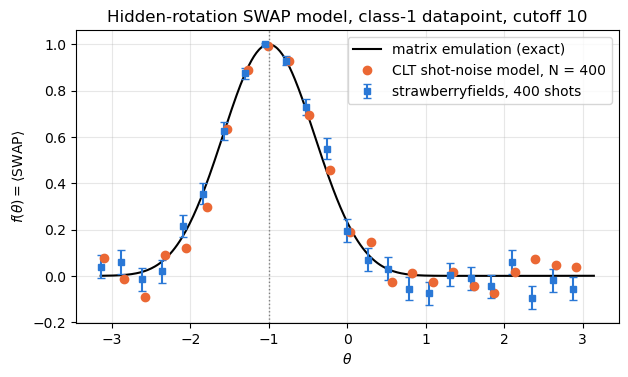

In [5]:
theta_fine = np.linspace(-np.pi, np.pi, 400)
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(theta_fine, [f_exact(t) for t in theta_fine], color="black", lw=1.5, label="matrix emulation (exact)")
ax.errorbar(thetas, f_sf, yerr=sigma, fmt="s", ms=5, capsize=3, color=COLORS["sf"],
            label=f"strawberryfields, {n_shots} shots")
ax.plot(thetas + 0.04, f_clt, "o", ms=6, color=COLORS["clt"],  # shifted slightly for visibility
        label=f"CLT shot-noise model, N = {n_shots}")
ax.axvline(-1, color="grey", ls=":", lw=1)
ax.set_xlabel(r"$\theta$")
ax.set_ylabel(r"$f(\theta) = \langle \mathrm{SWAP} \rangle$")
ax.set_title(f"Hidden-rotation SWAP model, class-{label} datapoint, cutoff {d}")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

## 3. Real and simulated shot noise

Repeated estimates at $\theta = 0.3$:

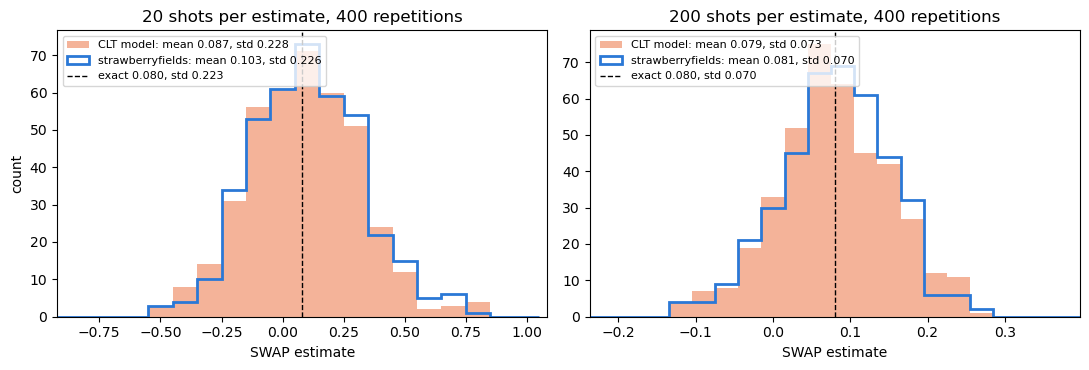

In [6]:
theta_fixed = 0.3
n_repetitions = 400
f_fixed = f_exact(theta_fixed)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, n in zip(axes, (20, 200)):
    sf_c = SFRotationSwapCircuit(d, n)
    clt_c = RotationSwapShotCircuit(d, swap_operator(d), n)
    sf_estimates = np.array([sf_c.forward(np.array([theta_fixed]), x) for _ in range(n_repetitions)])
    clt_estimates = np.array([clt_c.forward(np.array([theta_fixed]), x).item() for _ in range(n_repetitions)])

    std = np.sqrt((1 - f_fixed**2) / n)
    step = 2 / n * max(1, round(0.45 * std / (2 / n)))  # bin edges aligned with the possible sf values (steps of 2/N)
    bins = np.arange(-1 - 1 / n, 1 + step, step)
    ax.hist(clt_estimates, bins, color=COLORS["clt"], alpha=0.5,
            label=f"CLT model: mean {clt_estimates.mean():.3f}, std {clt_estimates.std():.3f}")
    ax.hist(sf_estimates, bins, histtype="step", lw=2, color=COLORS["sf"],
            label=f"strawberryfields: mean {sf_estimates.mean():.3f}, std {sf_estimates.std():.3f}")
    ax.axvline(f_fixed, color="black", ls="--", lw=1, label=f"exact {f_fixed:.3f}, std {std:.3f}")
    ax.set_xlim(f_fixed - 4.5 * std, f_fixed + 4.5 * std)
    ax.set_xlabel("SWAP estimate")
    ax.set_title(f"{n} shots per estimate, {n_repetitions} repetitions")
    ax.legend(fontsize=8, loc="upper left")
axes[0].set_ylabel("count")
fig.tight_layout()
plt.show()

## 4. Parameter-shift rules

On hardware the gradient comes from the model evaluated at shifted parameters. The two-term rule
$f'(\theta) = \tfrac12[f(\theta+\tfrac\pi2) - f(\theta-\tfrac\pi2)]$ is exact only for a single frequency. A rotation
on a Fock space truncated at $d$ levels needs the generalised rule of Wierichs et al.
([arXiv:2107.12390](https://arxiv.org/abs/2107.12390)) with $R = d$ terms, `gradients.generalised_parameter_shift`:

In [7]:
def f_numpy(params, x):
    return matrix_circuit.forward(torch.tensor(params), x).item()

def autograd_derivative(theta):
    p = torch.tensor([theta], dtype=torch.float64, requires_grad=True)
    matrix_circuit.forward(p, x).backward()
    return p.grad.item()

theta_grid = np.linspace(-np.pi, np.pi, 41)
grad_autograd = np.array([autograd_derivative(t) for t in theta_grid])
grad_two_term = np.array([parameter_shift(f_numpy, np.array([t]), 0, circuit_args=(x,)) for t in theta_grid])
grad_general = np.array([generalised_parameter_shift(f_numpy, np.array([t]), 0, circuit_args=(x,), n_frequencies=d)
                         for t in theta_grid])

print(f"max |two-term - autograd|          = {np.max(np.abs(grad_two_term - grad_autograd)):.3f}")
print(f"max |generalised (R = d) - autograd| = {np.max(np.abs(grad_general - grad_autograd)):.1e}")

max |two-term - autograd|          = 0.920
max |generalised (R = d) - autograd| = 1.3e-14


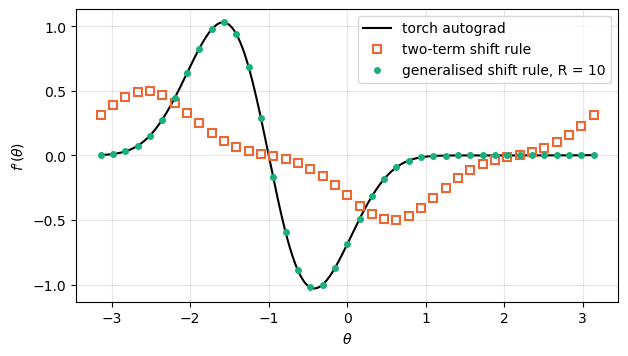

In [8]:
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(theta_fine, [autograd_derivative(t) for t in theta_fine], color="black", lw=1.5, label="torch autograd")
ax.plot(theta_grid, grad_two_term, "s", ms=6, mfc="none", mew=1.5, color=COLORS["clt"], label="two-term shift rule")
ax.plot(theta_grid, grad_general, "o", ms=4, color=COLORS["general"], label=f"generalised shift rule, R = {d}")
ax.set_xlabel(r"$\theta$")
ax.set_ylabel(r"$f'(\theta)$")
ax.grid(alpha=0.3)
ax.legend()
plt.show()